<a href="https://colab.research.google.com/github/laalainf-design/FOOD-DELIVERY-EDA-ML/blob/main/FOOD_DELIVERY_EDA_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("food_delivery_dataset.csv")
print("Shape:", df.shape)
df.head()
df.info()

Shape: (38964, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38964 entries, 0 to 38963
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           38964 non-null  object 
 1   Delivery_person_ID           38964 non-null  object 
 2   Delivery_person_Age          37945 non-null  float64
 3   Delivery_person_Ratings      37909 non-null  float64
 4   Restaurant_latitude          38964 non-null  float64
 5   Restaurant_longitude         38964 non-null  float64
 6   Delivery_location_latitude   38964 non-null  float64
 7   Delivery_location_longitude  38964 non-null  float64
 8   Order_Date                   38964 non-null  object 
 9   Time_Orderd                  38129 non-null  object 
 10  Time_Order_picked            38964 non-null  object 
 11  Weather_conditions           38964 non-null  object 
 12  Road_traffic_density         38964 non-null  object 
 1

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct}).sort_values("missing", ascending=False)

,missing,percent
Delivery_person_Ratings,1055,2.71
Delivery_person_Age,1019,2.62
Time_Orderd,835,2.14
Delivery_person_ID,0,0.00
Restaurant_latitude,0,0.00
ID,0,0.00
Restaurant_longitude,0,0.00
Delivery_location_latitude,0,0.00
Delivery_location_longitude,0,0.00
Order_Date,0,0.00


In [4]:
cat_cols = ["Weather_conditions", "Road_traffic_density", "Type_of_order",
            "Type_of_vehicle", "Festival", "City", "delivery_speed"]

for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Weather_conditions ---
Weather_conditions
Fog           6660
Stormy        6572
Cloudy        6563
Sandstorms    6489
Windy         6436
Sunny         6244
Name: count, dtype: int64

--- Road_traffic_density ---
Road_traffic_density
Low       13139
Jam       12414
Medium     9556
High       3855
Name: count, dtype: int64

--- Type_of_order ---
Type_of_order
Snack     9815
Meal      9774
Drinks    9751
Buffet    9624
Name: count, dtype: int64

--- Type_of_vehicle ---
Type_of_vehicle
motorcycle          22942
scooter             12926
electric_scooter     3096
Name: count, dtype: int64

--- Festival ---
Festival
No     38180
Yes      784
Name: count, dtype: int64

--- City ---
City
Metropolitian    30036
Urban             8782
Semi-Urban         146
Name: count, dtype: int64

--- delivery_speed ---
delivery_speed
Average    19982
Fast       10164
Slow        8818
Name: count, dtype: int64



In [8]:
# data dobara load kar rahe hain
df = pd.read_csv("food_delivery_dataset.csv")

# time 3 tarah ka likha hua hai, isko minutes mein badalte hain
def get_minutes(t):
    if pd.isnull(t):
        return np.nan
    t = str(t)
    if ":" in t:
        parts = t.split(":")
        return (int(parts[0]) * 60 + int(parts[1])) % 1440
    else:
        return round(float(t) * 1440) % 1440

df["order_min"] = df["Time_Orderd"].apply(get_minutes)
df["pick_min"] = df["Time_Order_picked"].apply(get_minutes)

# date se month aur din nikale
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%d-%m-%Y")
df["month"] = df["Order_Date"].dt.month
df["day"] = df["Order_Date"].dt.day_name()

# pickup ka hour aur wait time
df["pickup_hour"] = (df["pick_min"] // 60).astype(int)
df["wait_time"] = (df["pick_min"] - df["order_min"]) % 1440

# delivery person id se city code
df["city_code"] = df["Delivery_person_ID"].str.extract(r"^([A-Z]+?)RES")

# missing values ko median se bhar diya
df["Delivery_person_Age"] = df["Delivery_person_Age"].fillna(df["Delivery_person_Age"].median())
df["Delivery_person_Ratings"] = df["Delivery_person_Ratings"].fillna(df["Delivery_person_Ratings"].median())
df["wait_time"] = df["wait_time"].fillna(df["wait_time"].median())

# City ki spelling theek ki
df["City"] = df["City"].replace("Metropolitian", "Metropolitan")

# check
print(df.shape)
print(df[["pick_min", "pickup_hour", "wait_time", "Delivery_person_Age", "Delivery_person_Ratings"]].isnull().sum())

(38964, 29)
pick_min                   0
pickup_hour                0
wait_time                  0
Delivery_person_Age        0
Delivery_person_Ratings    0
dtype: int64


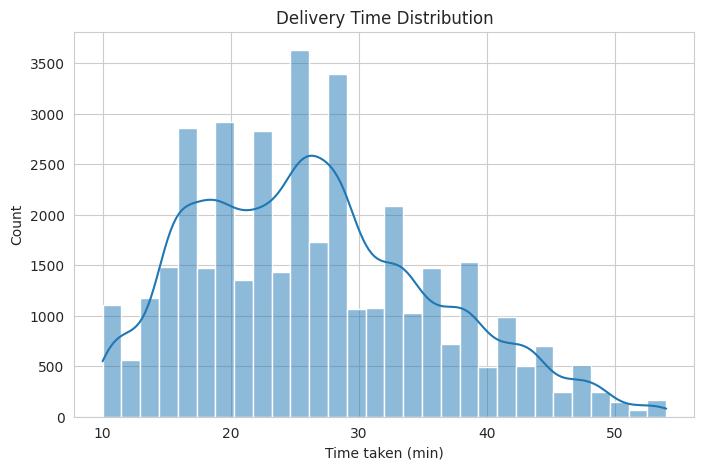

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Time_taken (min)"], bins=30, kde=True)
plt.title("Delivery Time Distribution")
plt.xlabel("Time taken (min)")
plt.show()

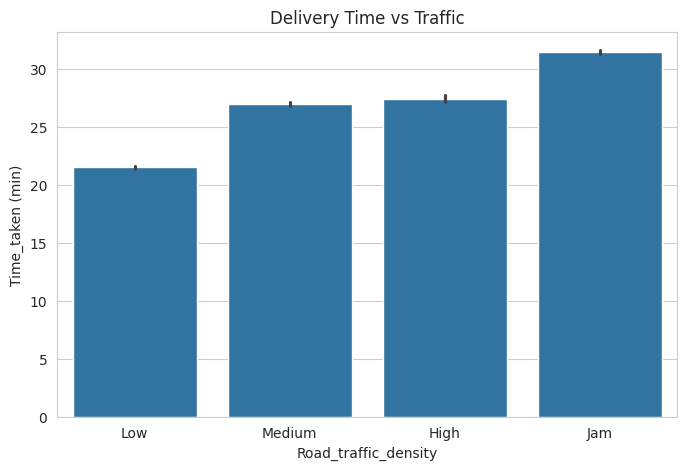

In [10]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Road_traffic_density", y="Time_taken (min)", order=["Low", "Medium", "High", "Jam"])
plt.title("Delivery Time vs Traffic")
plt.show()

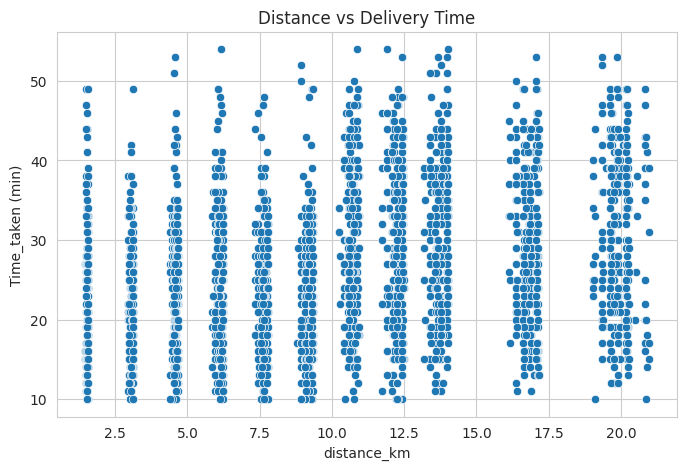

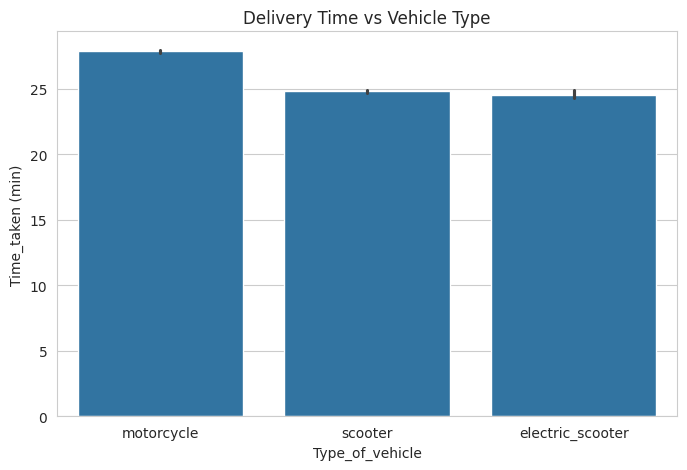

In [12]:
small = df.sample(3000, random_state=1)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=small, x="distance_km", y="Time_taken (min)")
plt.title("Distance vs Delivery Time")
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Type_of_vehicle", y="Time_taken (min)")
plt.title("Delivery Time vs Vehicle Type")
plt.show()

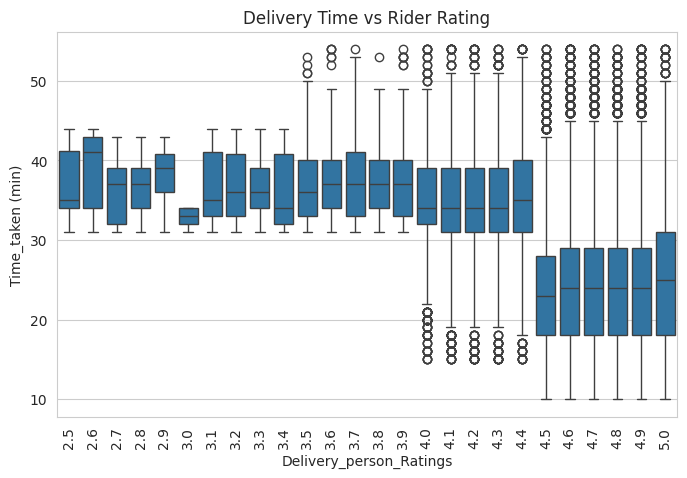

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Delivery_person_Ratings", y="Time_taken (min)")
plt.title("Delivery Time vs Rider Rating")
plt.xticks(rotation=90)
plt.show()

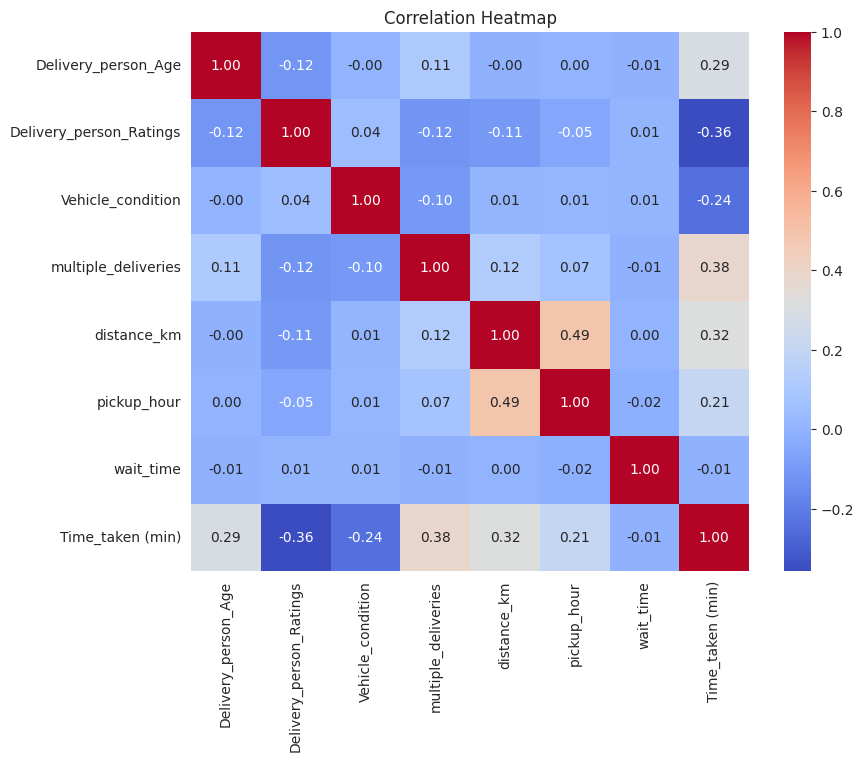

In [14]:
num_cols = ["Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition",
            "multiple_deliveries", "distance_km", "pickup_hour", "wait_time",
            "Time_taken (min)"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

CLEANED DATA

In [15]:
df.to_csv("food_delivery_cleaned.csv", index=False)

from google.colab import files
files.download("food_delivery_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MACHINE LEARNING


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [17]:

y = df["Time_taken (min)"]


drop_cols = ["Time_taken (min)",
             "delivery_speed",
             "ID", "Delivery_person_ID",
             "Order_Date", "Time_Orderd", "Time_Order_picked",
             "order_min", "pick_min",
             "Restaurant_latitude", "Restaurant_longitude",
             "Delivery_location_latitude", "Delivery_location_longitude"]

X = df.drop(columns=drop_cols)

print(X.columns.tolist())
X.head()

['Delivery_person_Age', 'Delivery_person_Ratings', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'distance_km', 'month', 'day', 'pickup_hour', 'wait_time', 'city_code']


,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,distance_km,month,day,pickup_hour,wait_time,city_code
0,36.0,4.2,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitan,10.280582,2,Saturday,22,15.0,DEH
1,21.0,4.7,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitan,6.242319,2,Sunday,15,10.0,KOC
2,23.0,4.7,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitan,13.787860,3,Friday,17,10.0,PUNE
3,34.0,4.3,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitan,2.930258,2,Sunday,9,10.0,LUDH
4,24.0,4.7,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitan,19.396618,2,Monday,20,15.0,KNP


In [18]:
X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
X.head()

X shape: (38964, 51)


,Delivery_person_Age,Delivery_person_Ratings,Vehicle_condition,multiple_deliveries,distance_km,month,pickup_hour,wait_time,Weather_conditions_Fog,Weather_conditions_Sandstorms,...,city_code_KNP,city_code_KOC,city_code_KOL,city_code_LUDH,city_code_MUM,city_code_MYS,city_code_PUNE,city_code_RANCHI,city_code_SUR,city_code_VAD
0,36.0,4.2,2,3.0,10.280582,2,22,15.0,True,False,...,False,False,False,False,False,False,False,False,False,False
1,21.0,4.7,1,1.0,6.242319,2,15,10.0,False,False,...,False,True,False,False,False,False,False,False,False,False
2,23.0,4.7,1,1.0,13.787860,3,17,10.0,False,True,...,False,False,False,False,False,False,True,False,False,False
3,34.0,4.3,0,0.0,2.930258,2,9,10.0,False,True,...,False,False,False,True,False,False,False,False,False,False
4,24.0,4.7,1,1.0,19.396618,2,20,15.0,True,False,...,True,False,False,False,False,False,False,False,False,False


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (31171, 51)
Test: (7793, 51)


In [20]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

print("Linear Regression")
print("R2:", r2_score(y_test, lr_pred))
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))

Linear Regression
R2: 0.5900408514014088
MAE: 4.693957468002862
RMSE: 5.906776824611322


In [21]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest")
print("R2:", r2_score(y_test, rf_pred))
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))

Random Forest
R2: 0.8174400342658119
MAE: 3.1373822661362767
RMSE: 3.9416952478497875


In [22]:
result = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2": [r2_score(y_test, lr_pred), r2_score(y_test, rf_pred)],
    "MAE": [mean_absolute_error(y_test, lr_pred), mean_absolute_error(y_test, rf_pred)]
})
print(result)

               Model        R2       MAE
0  Linear Regression  0.590041  4.693957
1      Random Forest  0.817440  3.137382


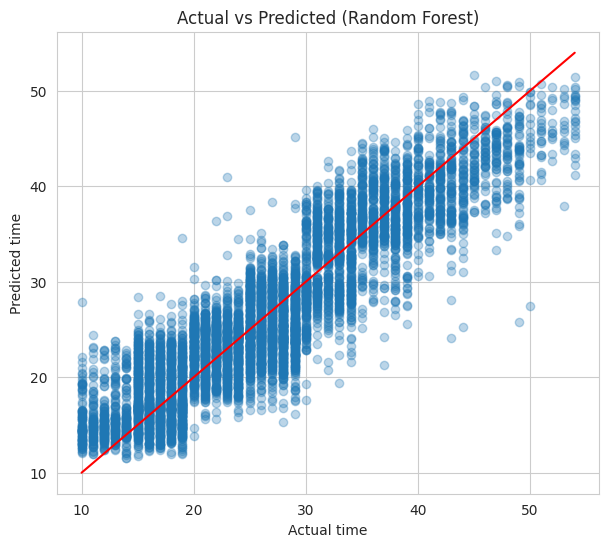

In [23]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, rf_pred, alpha=0.3)
plt.plot([10, 54], [10, 54], color="red")
plt.xlabel("Actual time")
plt.ylabel("Predicted time")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()

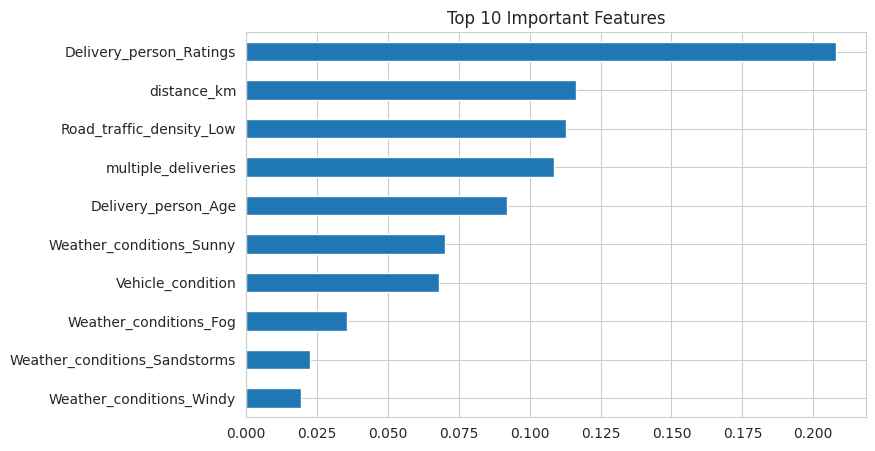

In [24]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features")
plt.show()

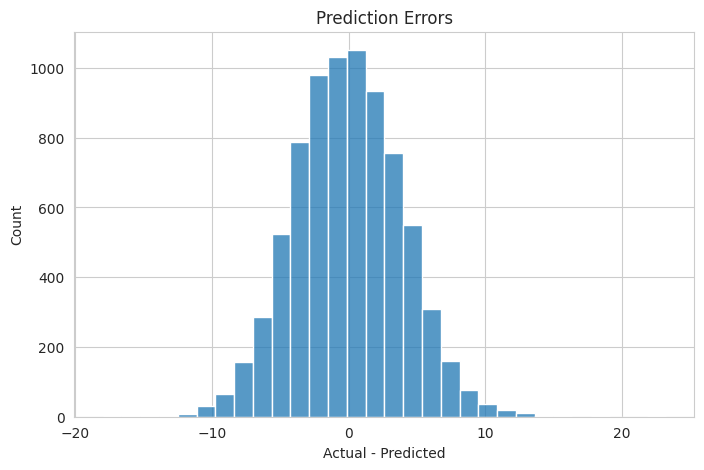

In [25]:
errors = y_test - rf_pred

plt.figure(figsize=(8, 5))
sns.histplot(errors, bins=30)
plt.title("Prediction Errors")
plt.xlabel("Actual - Predicted")
plt.show()